In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
import pickle
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame
from sklearn.model_selection import train_test_split
import sys

# Get project root and add to path
project_root = Path().resolve().parents[0] if Path().resolve().name == 'notebooks' else Path().resolve()
if project_root.name != 'mtl-mar':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from utils import DATA_RAW, DATA_INTERIM

In [2]:
def find_nearest(value,vector):
    vector = np.float64(vector)-np.float64(value);
    return np.argmin(np.abs(vector))

In [ ]:
data_path = DATA_RAW / "labels"
sed_labels_file = "sedrate_deep.csv"

df = pd.read_csv(Path(data_path / sed_labels_file))


In [4]:
df

,Unnamed: 0,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,0,-68.133000,-126.750000,0.58000,0.36192
1,1,-68.117000,-130.733000,0.77000,0.50050
2,2,-68.067000,-106.800000,0.74000,0.46176
3,3,-68.050000,-159.817000,1.15000,0.74750
4,4,-68.050000,174.600000,0.97000,0.68094
...,...,...,...,...,...
7904,7912,-71.958333,171.875000,0.00001,0.00001
7905,7913,-72.041667,-51.875000,0.00001,0.00001
7906,7914,-72.041667,171.958333,0.00001,0.00001
7907,7915,-72.208333,170.208333,0.00001,0.00001


/tmp/ipykernel_2261345/67302214.py:6: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,MAR(g/cm**2/ka)
count,7713.000000,7713.000000,7713.000000
mean,12.210538,46.923092,67.982287
std,35.646465,90.719889,99.553314
min,-76.400000,-179.483000,0.000000
25%,5.970000,-25.625000,0.865280
50%,19.071398,113.162072,18.850000
75%,23.600000,118.245406,119.600000
max,89.000000,179.483000,3369.600000


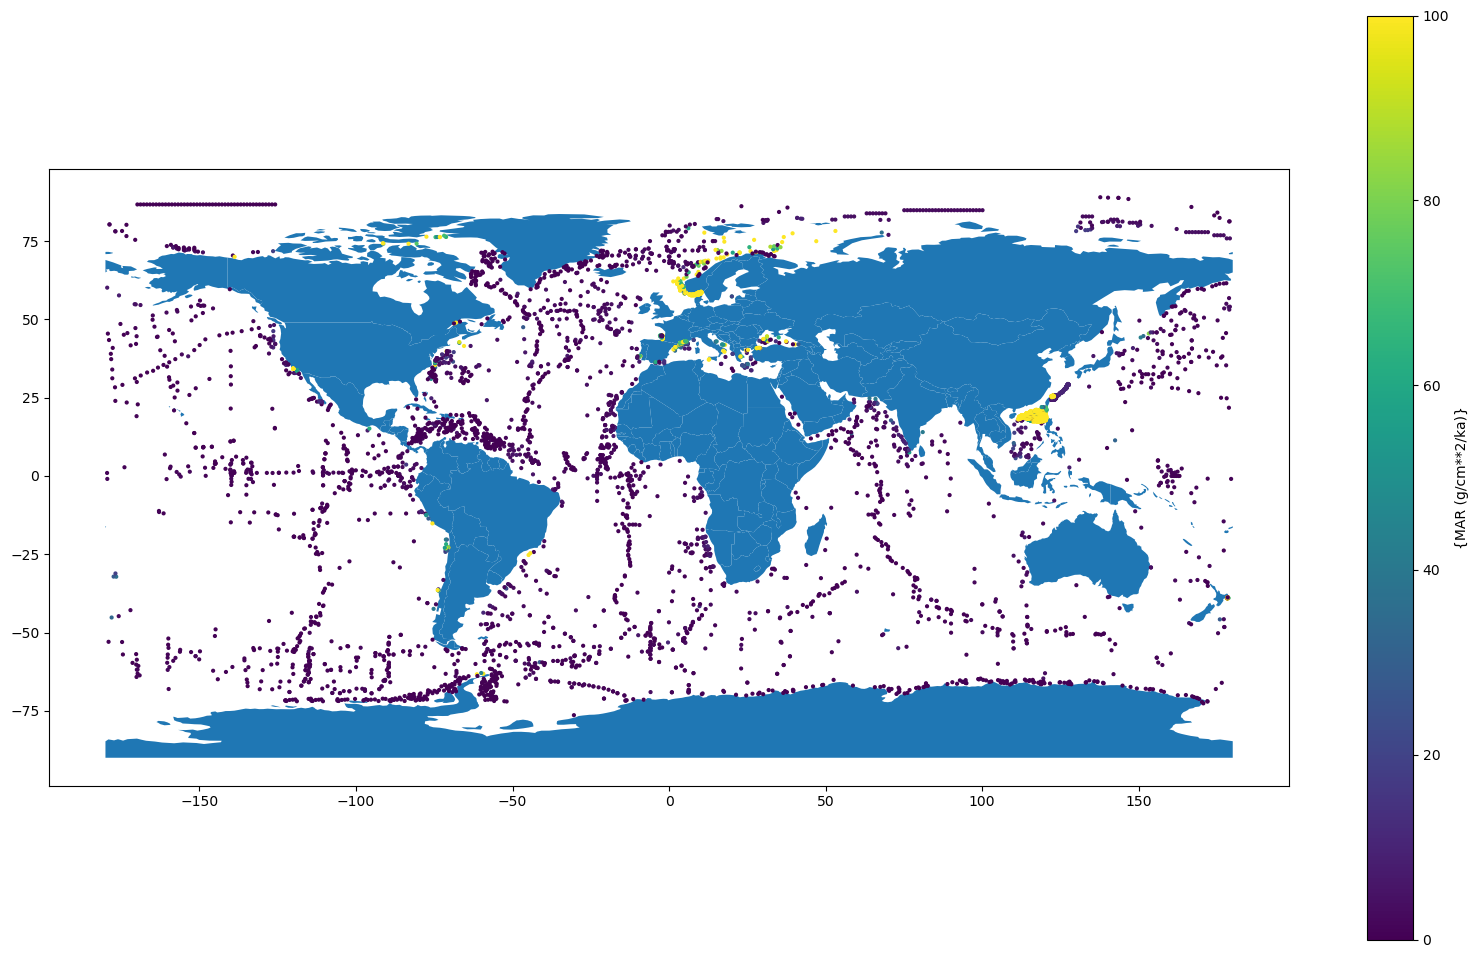

In [5]:

df = df[["Latitude","Longitude","MAR(g/cm**2/ka)"]]
df = df[df["Longitude"]>-180]
df = df.dropna(how="any")
#df = df[df["Sedimentation rate [cm/ka]"]<5000]

world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
gdf = GeoDataFrame(df, geometry=geometry)  
gdf.plot(ax = world.plot(figsize = (20, 12)), column = df["MAR(g/cm**2/ka)"], vmin = 0, vmax = 100,legend = True, legend_kwds={"label":"{MAR (g/cm**2/ka)}"}, markersize = 4);

df.describe()

In [6]:
df

,Latitude,Longitude,MAR(g/cm**2/ka)
0,-68.133000,-126.750000,0.36192
1,-68.117000,-130.733000,0.50050
2,-68.067000,-106.800000,0.46176
3,-68.050000,-159.817000,0.74750
4,-68.050000,174.600000,0.68094
...,...,...,...
7904,-71.958333,171.875000,0.00001
7905,-72.041667,-51.875000,0.00001
7906,-72.041667,171.958333,0.00001
7907,-72.208333,170.208333,0.00001


In [7]:
df["Longitude"].max()

179.483

In [ ]:
restrepo_features_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)



510

In [ ]:
feature_selection = pd.read_csv(DATA_INTERIM / "selectedFeatureLists" / "selectedfeatures_v_men.txt").values
#feature_selection = pd.read_csv(Path("restrepoHighResFeaturesRaw-50.txt")).values



selection_filter = np.zeros(len(restrepo_files), dtype=bool)
for idx, feature_name in enumerate(filenames):
    if feature_name in feature_selection: # drop '.nc' from feature names #drop .grd
        selection_filter[idx] = True

In [10]:
filenames

[]

In [11]:
feature_selection = pd.read_csv(Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/selectedFeatureLists/selectedfeatures_v_men.txt")).values
#feature_selection = pd.read_csv(Path("restrepoHighResFeaturesRaw-50.txt")).values



selection_filter = np.zeros(len(restrepo_files), dtype=bool)

In [12]:
selected_files = []
for file in restrepo_files:
    if file in feature_selection:
        selected_files.append(file)

print(selected_files)

['DERIVATIVE_lithology_grain_size_Everardo_global_8.nc', 'EOT20_tidal_ratio_5arcmin_interp_land.nc', 'EOT20_u3_5arcmin_interp_land.nc', 'EOT20_umax_5arcmin_interp_land.nc', 'EOT20_urms_5arcmin_interp_land.nc', 'GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc', 'GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc', 'GL_DIST_TO_COAST_KM_ETOPO.5m.grd', 'GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd', 'GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd', 'GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd', 'GL_HEATFLUX_MWM2_Becker.5m.nc', 'GL_HEATFLUX_MWM2_Becker_r50km_men.nc', 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.r50km.men.5m.grd', 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.r50km.men.5m.grd', 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.r50km.men.5m.grd', 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.r50km.men.5m.grd

In [13]:
len(feature_selection)

110

In [14]:
restrepo_files = selected_files

In [15]:
restrepo_files

['DERIVATIVE_lithology_grain_size_Everardo_global_8.nc',
 'EOT20_tidal_ratio_5arcmin_interp_land.nc',
 'EOT20_u3_5arcmin_interp_land.nc',
 'EOT20_umax_5arcmin_interp_land.nc',
 'EOT20_urms_5arcmin_interp_land.nc',
 'GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc',
 'GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc',
 'GL_DIST_TO_COAST_KM_ETOPO.5m.grd',
 'GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd',
 'GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd',
 'GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd',
 'GL_HEATFLUX_MWM2_Becker.5m.nc',
 'GL_HEATFLUX_MWM2_Becker_r50km_men.nc',
 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_POC_TGCYR-1_O

In [16]:
rootgrp = xr.open_dataset(Path(restrepo_features_path / restrepo_files[0]), format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']
lat_labels = []
lon_labels = []

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.so'.
libgmt.so: cannot open shared object file: No such file or directory
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [17]:
latitudes = np.array(df["Latitude"])
longitudes = np.array(df["Longitude"])
save_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men")
np.save(Path(save_path / "numpy_lat"),latitudes)
np.save(Path(save_path / "numpy_lon"),longitudes)

In [18]:
restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
restrepo_features[:] = np.nan
restrepo_X_mean = np.empty(0)
restrepo_X_std = np.empty(0)
# Create latitude array from -90 to 90 with 5 arc minute spacing
# 5 arc minutes = 5/60 = 0.0833333 degrees
# Number of points = (90 - (-90)) / (5/60) = 2160
latitudes = np.linspace(-90, 90, 2160)
longitudes = np.linspace(-180, 180, 4320)
file_idx = -1
corrupted_files = 0
lat_idx = []
lon_idx = []
for data_idx in range(0,len(df)):
    lat_idx.append(find_nearest(df.iloc[data_idx,0], latitudes))
    lon_idx.append(find_nearest(df.iloc[data_idx,1], longitudes))

for file in restrepo_files[0:len(restrepo_files)]:
    #if file in feature_selection:

    file_idx += 1
    try: 
        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
    except:
        restrepo_X_mean = np.append(restrepo_X_mean,np.nan)
        restrepo_X_std = np.append(restrepo_X_std,np.nan)
        corrupted_files = corrupted_files + 1
        continue

    #remove labels if the elevation is greatere than 10 m. There are a lot of points, especially in the middle east and the area between dead sea and the caspian sea, whcih is obviously located wrong.
    #this needs to be backtracked, but until then we do not use these points for training.



#     latitudes = rootgrp.variables['lats'] # in theory all the same
#     longitudes = rootgrp.variables['lons']

    # dataset = rootgrp.variables['z']
    # if Features_Phrampus_noNAN is used just use rootgrp.variables['data']
    dataset = rootgrp.variables['data']
    #print(dataset)

    restrepo_X_mean = np.append(restrepo_X_mean,np.nanmean(dataset))
    restrepo_X_std = np.append(restrepo_X_std,np.nanstd(dataset))
    # if file == "GL_LAND_IS_1.0_ETOPO2v2.5m.nc":
    #     dataset = rootgrp.variables['data']
    # else:
    #dataset = rootgrp.variables['data']
    if file == "SF_POROSITY_FRC.5m_with_coords_flip.nc":
        porosity_fileidx = file_idx


    if file == "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd":
        for data_idx in range(0,len(df)):
            if dataset[lat_idx[data_idx], lon_idx[data_idx]] > 5:
                restrepo_features[data_idx, file_idx] = np.nan
                #print(dataset[lat_idx[data_idx], lon_idx[data_idx]] )
            else:
                restrepo_features[data_idx, file_idx] = dataset[lat_idx[data_idx], lon_idx[data_idx]]

            # incliding nan values so that it can be removed later while training

            # latitudes_labels.append(latitudes[lat_idx])
            # longitudes_labels.append(longitudes[lon_idx])

        print("file " + str(file_idx) + " :" + str(file)+  " done!")


    else:
        for data_idx in range(0,len(df)):
            restrepo_features[data_idx, file_idx] = dataset[lat_idx[data_idx], lon_idx[data_idx]]
            # latitudes_labels.append(latitudes[lat_idx])
            # longitudes_labels.append(longitudes[lon_idx])

        print("file " + str(file_idx) + " :" + str(file)+  " done!")


print("corrupted files: " + str(corrupted_files))


file 0 :DERIVATIVE_lithology_grain_size_Everardo_global_8.nc done!
file 1 :EOT20_tidal_ratio_5arcmin_interp_land.nc done!
file 2 :EOT20_u3_5arcmin_interp_land.nc done!
file 3 :EOT20_umax_5arcmin_interp_land.nc done!
file 4 :EOT20_urms_5arcmin_interp_land.nc done!
file 5 :GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc done!
file 6 :GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc done!
file 7 :GL_DIST_TO_COAST_KM_ETOPO.5m.grd done!
file 8 :GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd done!
file 9 :GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd done!
file 10 :GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd done!
file 11 :GL_HEATFLUX_MWM2_Becker.5m.nc done!
file 12 :GL_HEATFLUX_MWM2_Becker_r50km_men.nc done!
file 13 :GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd done!
file 14 :GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.r50km.men.5m.grd done!
file 15 :GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.5m.grd done!
file 16 :GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.r50km.men.5m.

In [19]:
print("corrupted files: " + str(corrupted_files))

features = np.concatenate([restrepo_features], axis = 1)
X_mean = np.concatenate([restrepo_X_mean])
X_std = np.concatenate([restrepo_X_std])
features.shape


save_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men")
np.save(Path(save_path / "numpy_features"), restrepo_features)
np.save(Path(save_path / "numpy_labels"), df["MAR(g/cm**2/ka)"].values)
np.save(Path(save_path / "features_mean"),restrepo_X_mean)
np.save(Path(save_path / "features_std"),restrepo_X_std)


corrupted files: 0


In [20]:
porosity_fileidx

44

# Make Global Features

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
from pathlib import Path
import gc
from skimage.transform import resize
#from time import start
from multiprocessing import pool

In [22]:
restrepo_input_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")


restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_input_path):
    restrepo_files.extend(filenames)
    break

restrepo_files.sort()
print(len(restrepo_files))

datasets = []
ii = 0
corrupted_files = 0

# land_file = Path(restrepo_input_path / "GL_LAND_IS_1.0_ETOPO2v2.5m.nc")
# rootgrp = xr.open_dataset(land_file)
# dataset = rootgrp['data']
# plt.imshow(dataset)

# np.save(Path(restrepo_input_path.parent / "is_land_map"), np.asarray(dataset).astype(np.bool))

510


In [23]:
feature_selection = pd.read_csv(Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/selectedFeatureLists/selectedfeatures_v_men.txt")).values

In [24]:
for file in restrepo_files[0:len(restrepo_files)]:   
    
    if file in feature_selection:
        try: 

            rootgrp = xr.open_dataset(Path(restrepo_input_path / file), format = 'NETCDF4')
        except:
            datasets.append(np.nan)
            corrupted_files = corrupted_files + 1
            continue
        # if file == "POROSITY_global_prediction.grd":
        #     dataset = rootgrp.variables['z']
        # dataset = rootgrp.variables['data'] if Features_Phrampus_noNan is used
        if ii==182:
            dataset = rootgrp.variables['data']

        else:
            dataset = rootgrp.variables['data']

        #plt.imshow(dataset)
        #dataset = rootgrp.variables['z']
        print(np.where(np.isnan(dataset)))
        print(file)
        datasets.append(dataset)
        ii+=1
        print("File " + str(ii) + " of " + str(len(restrepo_files)))

print(str(corrupted_files) + " corrupted files")

(array([], dtype=int64), array([], dtype=int64))
DERIVATIVE_lithology_grain_size_Everardo_global_8.nc
File 1 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_tidal_ratio_5arcmin_interp_land.nc
File 2 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_u3_5arcmin_interp_land.nc
File 3 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_umax_5arcmin_interp_land.nc
File 4 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_urms_5arcmin_interp_land.nc
File 5 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 6 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 7 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_DIST_TO_COAST_KM_ETOPO.5m.grd
File 8 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd
F

In [25]:
#output_path = Path(Path().resolve().parents[2] / "Data" / "RestrepoKNNsSed" / "WorldFeaturesAll")#ChlorWorldFeatures
output_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_predict_men/")


#num_proc=16

chunks = 360 # dataset.shape[0]/chunks must be int
#chunks_mp=1/num_proc
lat_step = int(dataset.shape[0]/chunks)

In [26]:
import numpy as np
from multiprocessing import Pool
from pathlib import Path

def process_chunk(ii):
    feature_chunk = np.zeros([int(dataset.shape[0] / chunks * dataset.shape[1]), len(datasets)])

    for idx in range(len(datasets)):
        if datasets[idx] is not np.nan:
            feature_chunk[:, idx] = np.asarray(datasets[idx][ii * lat_step:ii * lat_step + lat_step, :]).flatten(order="C")
        else:
            feature_chunk[:, idx] = np.nan

    save_name = "Sed_world_feature_" + str(ii).zfill(3)
    np.save(Path(output_path / save_name), feature_chunk)
    print("Chunk " + str(ii + 1) + " of " + str(chunks) + " written!")

if __name__ == '__main__':
    chunks = 360  # Adjust the number of chunks as per your requirement
    pool = Pool(processes=64)  # Adjust the number of processes as per your requirement

    pool.map(process_chunk, range(chunks))

    pool.close()
    pool.join()

Chunk 75 of 360 written!Chunk 47 of 360 written!Chunk 89 of 360 written!Chunk 105 of 360 written!Chunk 15 of 360 written!Chunk 3 of 360 written!Chunk 97 of 360 written!Chunk 45 of 360 written!Chunk 31 of 360 written!
Chunk 29 of 360 written!








Chunk 39 of 360 written!Chunk 25 of 360 written!

Chunk 11 of 360 written!Chunk 7 of 360 written!
Chunk 33 of 360 written!

Chunk 5 of 360 written!
Chunk 41 of 360 written!
Chunk 57 of 360 written!Chunk 27 of 360 written!

Chunk 23 of 360 written!
Chunk 63 of 360 written!Chunk 43 of 360 written!

Chunk 49 of 360 written!
Chunk 71 of 360 written!Chunk 13 of 360 written!
Chunk 35 of 360 written!

Chunk 69 of 360 written!Chunk 19 of 360 written!

Chunk 103 of 360 written!
Chunk 37 of 360 written!
Chunk 17 of 360 written!
Chunk 67 of 360 written!Chunk 85 of 360 written!

Chunk 95 of 360 written!Chunk 119 of 360 written!
Chunk 61 of 360 written!

Chunk 83 of 360 written!
Chunk 51 of 360 written!
Chunk 79 of 360 written!
Chunk 55 of 360 written!


# Make Global Features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
from pathlib import Path
import gc
from skimage.transform import resize
#from time import start
from multiprocessing import pool

In [2]:
restrepo_input_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/")


restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_input_path):
    restrepo_files.extend(filenames)
    break

restrepo_files.sort()
print(len(restrepo_files))

datasets = []
ii = 0
corrupted_files = 0

# land_file = Path(restrepo_input_path / "GL_LAND_IS_1.0_ETOPO2v2.5m.nc")
# rootgrp = xr.open_dataset(land_file)
# dataset = rootgrp['data']
# plt.imshow(dataset)

# np.save(Path(restrepo_input_path.parent / "is_land_map"), np.asarray(dataset).astype(np.bool))

510


In [3]:
feature_selection = pd.read_csv(Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/selectedFeatureLists/selectedfeatures_v_men.txt")).values

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.so'.
libgmt.so: cannot open shared object file: No such file or directory
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


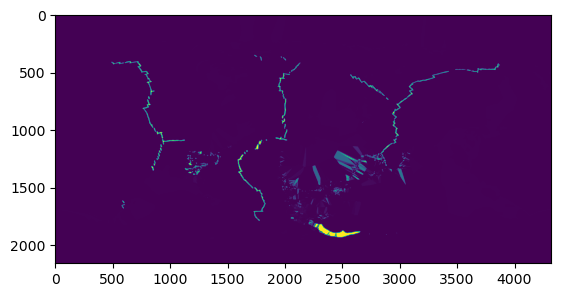

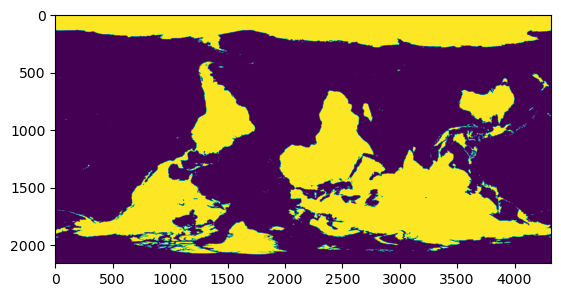

(2160, 4320)
DERIVATIVE_lithology_grain_size_Everardo_global_8.nc
File 1 of 510
(2160, 4320)
EOT20_tidal_ratio_5arcmin_interp_land.nc
File 2 of 510
(2160, 4320)
EOT20_u3_5arcmin_interp_land.nc
File 3 of 510
(2160, 4320)
EOT20_umax_5arcmin_interp_land.nc
File 4 of 510
(2160, 4320)
EOT20_urms_5arcmin_interp_land.nc
File 5 of 510
(2160, 4320)
GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 6 of 510
(2160, 4320)
GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 7 of 510
(2160, 4320)
GL_DIST_TO_COAST_KM_ETOPO.5m.grd
File 8 of 510
(2160, 4320)
GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd
File 9 of 510
(2160, 4320)
GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd
File 10 of 510
(2160, 4320)
GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd
File 11 of 510
(2160, 4320)
GL_HEATFLUX_MWM2_Becker.5m.nc
File 12 of 510
(2160, 4320)
GL_HEATFLUX_MWM2_Becker_r50km_men.nc
File 13 of 510
(2160, 4320)
GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd
F

In [4]:
# Load the land map (as in Visualisation.ipynb)
land_file = Path().resolve().parents[1] / "data" / "raw" / "island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1  # Set NaNs to 1 (land)
land_map = np.rot90(np.rot90(np.fliplr(land_map)))

# Coarsen the land map from (2160, 4320) to (216, 432) by taking every 10th element
land_map_coarse = land_map[::1, ::1]

ii = 0
for file in restrepo_files[0:len(restrepo_files)]:
    if file in feature_selection:

        try:
            rootgrp = xr.open_dataset(Path(restrepo_input_path / file), format='NETCDF4')
        except Exception as e:
            datasets.append(np.nan)
            corrupted_files = corrupted_files + 1
            print(f"Error loading {file}: {e}")
            continue

        dataset = rootgrp.variables['data']
        
        # Coarsen the dataset from (2160, 4320) to (216, 432) by taking every 10th element
        dataset_coarse = np.array(dataset)[::1, ::1]

        # Set dataset values to np.nan where land_map_coarse == 1 (land)
        if ii == 0:
            plt.imshow(dataset_coarse)
            plt.show()
            plt.imshow(land_map_coarse)
            plt.show()
            
        dataset_masked = dataset_coarse.copy()
        dataset_masked[land_map_coarse == 1] = np.nan
        print(dataset_masked.shape)
        print(file)

        
        datasets.append(dataset_masked)
        ii += 1
        print("File " + str(ii) + " of " + str(len(restrepo_files)))

print(str(corrupted_files) + " corrupted files")

In [5]:
#output_path = Path(Path().resolve().parents[2] / "Data" / "RestrepoKNNsSed" / "WorldFeaturesAll")#ChlorWorldFeatures
output_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/worldfeatures/WorldFeaturesAllnoNaN_SedTOC_explain/")


#num_proc=16

chunks = 1 # dataset.shape[0]/chunks must be int
#chunks_mp=1/num_proc
lat_step = int(dataset.shape[0]/chunks)

In [6]:
import numpy as np
from pathlib import Path
print(dataset_masked.shape[0])
print(dataset_masked.shape[1])
# Since there's only one chunk, process it directly without multiprocessing
feature_chunk = np.zeros([int(dataset_masked.shape[0] * dataset_masked.shape[1]), len(datasets)])

for idx in range(len(datasets)):
    if datasets[idx] is not np.nan:
        feature_chunk[:, idx] = np.asarray(datasets[idx]).flatten(order="C")
    else:
        feature_chunk[:, idx] = np.nan

save_name = "Sed_world_feature_000"
np.save(Path(output_path / save_name), feature_chunk)
print("World features saved to single file(for explainability(shap runs))!")

2160
4320
World features saved to single file(for explainability(shap runs))!


In [7]:
feature_chunk.shape

(9331200, 110)